<a href="https://colab.research.google.com/github/Shekhar94544513/NIC-Training/blob/main/Jan_Samadhan_Shekhar_Pratap_Singh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone Case Study: "Jan-Samadhan" — Smart Citizen Grievance Redressal & Policy Assistant
**Role:** NIC AI Taskforce Member  
**Goal:** Build a Proof-of-Concept (PoC) pipeline that analyzes historical grievance data (CPGRAMS-style), predicts department routing with supervised Machine Learning, uses Generative AI (with C.R.O.S.S. prompting and Retrieval-Augmented Generation) to assist officers, and applies privacy/governance safeguards such as PII masking[cite: 1, 2].

#Setup: Environment & Libraries



In [1]:
import os
import re
import json
import random
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
np.random.seed(42)
random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


#Phase 1: Data Exploration & Visualization
*Task 1.1 — Structured vs. Unstructured Data & Dataset Loading*


**Theory:** Public grievance portals such as CPGRAMS handle Big Data containing both structured data (fixed-schema fields like complaint_id, date, state, department, status, and resolution_days that support fast filtering and aggregation) and unstructured data (free-form text like complaint_narrative that captures rich context but requires preprocessing/NLP before modeling).

In [2]:
CSV_FILE = "jan_samadhan_grievances_500.csv"


def create_grievance_data(n_rows: int = 500) -> pd.DataFrame:
    templates = {
        "Ministry of Finance (Banking & Pensions)": [
            "My pension payment under NPS has been delayed for two months. Contact 9876543210.",
            "ATM debited Rs 10,000 twice at bank branch; refund not credited yet.",
            "PMJDY account KYC verification pending for 45 days despite submitting documents.",
        ],
        "Ministry of Road Transport & Highways": [
            "Severe potholes and waterlogging on highway causing daily traffic jams and accidents.",
            "FASTag balance deducted at toll plaza even though lane was blocked.",
            "Highway bypass streetlights not working for three weeks, unsafe at night.",
        ],
        "Ministry of Health & Family Welfare": [
            "Primary Health Centre lacks essential medicines and morning doctor is unavailable.",
            "Ayushman Bharat e-card portal showing error for senior citizen family member.",
            "Ambulance response took over 90 minutes during medical emergency in rural block.",
        ],
        "Department of Telecommunications": [
            "Broadband fiber connection down for 10 days; work from home severely affected. Call +91-9123456789.",
            "Unwanted promotional calls and SMS fraud continuing despite DND activation.",
            "Mobile number portability request rejected without valid reason by operator.",
        ],
        "Ministry of Rural Development": [
            "MGNREGA wages for last month's work have not been credited to job card holders.",
            "PMAY-G housing installment pending inspection approval since August.",
            "Village handpump broken and drinking water supply disrupted for several days.",
        ],
        "Ministry of Railways": [
            "Tatkal ticket refund not received after train cancellation; PNR status unclear.",
            "Unreserved coaches overcrowded and station washroom cleanliness needs urgent attention.",
        ],
        "Department of Consumer Affairs": [
            "E-commerce seller delivered defective appliance and refused replacement or refund.",
            "Gas agency charging extra delivery fee above subsidized cylinder rate.",
        ],
    }

    depts = list(templates.keys())
    weights = [0.24, 0.20, 0.17, 0.14, 0.12, 0.07, 0.06]
    states = [
        "Assam",
        "Uttar Pradesh",
        "Maharashtra",
        "Bihar",
        "Karnataka",
        "Tamil Nadu",
        "Delhi",
        "Rajasthan",
    ]
    statuses = ["Resolved", "In Progress", "Pending", "Escalated"]
    start_date = datetime(2026, 1, 1)

    rows = []
    for i in range(1, n_rows + 1):
        dept = random.choices(depts, weights=weights, k=1)[0]
        narrative = random.choice(templates[dept])
        if random.random() < 0.25:
            narrative = f"  {narrative}   Ref#{random.randint(1000, 9999)}!!  "

        dt = start_date + timedelta(days=random.randint(0, 315))
        res_days = (
            np.nan
            if random.random() < 0.18
            else max(1, int(np.random.normal(loc=14, scale=6)))
        )

        rows.append(
            {
                "complaint_id": f"CPG-2026-{i:04d}",
                "date": dt.strftime("%Y-%m-%d"),
                "state": random.choice(states) if random.random() > 0.03 else np.nan,
                "department": dept,
                "status": random.choice(statuses),
                "resolution_days": res_days,
                "complaint_narrative": narrative if random.random() > 0.02 else np.nan,
            }
        )

    return pd.DataFrame(rows)


df = create_grievance_data(500)
df.to_csv(CSV_FILE, index=False)
df = pd.read_csv(CSV_FILE)

structured_cols = [
    "complaint_id",
    "date",
    "state",
    "department",
    "status",
    "resolution_days",
]
unstructured_cols = ["complaint_narrative"]

print("Shape:", df.shape)
print("Structured columns:", structured_cols)
print("Unstructured columns:", unstructured_cols)
df.head()

Shape: (500, 7)
Structured columns: ['complaint_id', 'date', 'state', 'department', 'status', 'resolution_days']
Unstructured columns: ['complaint_narrative']


,complaint_id,date,state,department,status,resolution_days,complaint_narrative
0,CPG-2026-0001,2026-05-06,Uttar Pradesh,Department of Telecommunications,Escalated,16.0,Broadband fiber connection down for 10 days; w...
1,CPG-2026-0002,2026-01-14,Delhi,Ministry of Finance (Banking & Pensions),In Progress,13.0,My pension payment under NPS has been delayed ...
2,CPG-2026-0003,2026-03-23,Maharashtra,Ministry of Road Transport & Highways,In Progress,17.0,Severe potholes and waterlogging on highway ca...
3,CPG-2026-0004,2026-07-03,Assam,Ministry of Road Transport & Highways,Escalated,23.0,Severe potholes and waterlogging on highway ca...
4,CPG-2026-0005,2026-07-05,Assam,Department of Consumer Affairs,In Progress,12.0,Gas agency charging extra delivery fee above...


**Task 1.2 — Missing Values & Text Cleaning**--                          

**Theory:** Missing values in real civic records can distort aggregations or break model training. Dropping rows lacking a target label or complaint text keeps supervised learning clean, imputing numeric turnaround times with the departmental median avoids outlier skew, and normalizing text (lowercasing, removing noisy characters, collapsing extra spaces) reduces vocabulary noise.

In [3]:
print("Missing values before cleaning:\n", df.isna().sum())

df_clean = df.dropna(subset=["department", "complaint_narrative"]).copy()
df_clean["state"] = df_clean["state"].fillna("Unknown")
df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")
df_clean["month"] = df_clean["date"].dt.to_period("M").astype(str)
df_clean["resolution_days"] = df_clean.groupby("department")[
    "resolution_days"
].transform(lambda s: s.fillna(s.median()))


def clean_text(text: str) -> str:
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s.,-]+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


df_clean["cleaned_narrative"] = df_clean["complaint_narrative"].apply(clean_text)

print("\nMissing values after cleaning:\n", df_clean.isna().sum())
df_clean[["complaint_narrative", "cleaned_narrative"]].head(3)

Missing values before cleaning:
 complaint_id            0
date                    0
state                  10
department              0
status                  0
resolution_days        97
complaint_narrative    13
dtype: int64

Missing values after cleaning:
 complaint_id           0
date                   0
state                  0
department             0
status                 0
resolution_days        0
complaint_narrative    0
month                  0
cleaned_narrative      0
dtype: int64


,complaint_narrative,cleaned_narrative
0,Broadband fiber connection down for 10 days; w...,broadband fiber connection down for 10 days wo...
1,My pension payment under NPS has been delayed ...,my pension payment under nps has been delayed ...
2,Severe potholes and waterlogging on highway ca...,severe potholes and waterlogging on highway ca...


#Task 1.3 — Visual Insights
**Theory:** Visual analytics turns tabular logs into operational priorities. Ranking the top complaint-receiving departments highlights high-volume ministries for automation, while tracking monthly complaint volume alongside average resolution time exposes seasonal surges and processing delays.

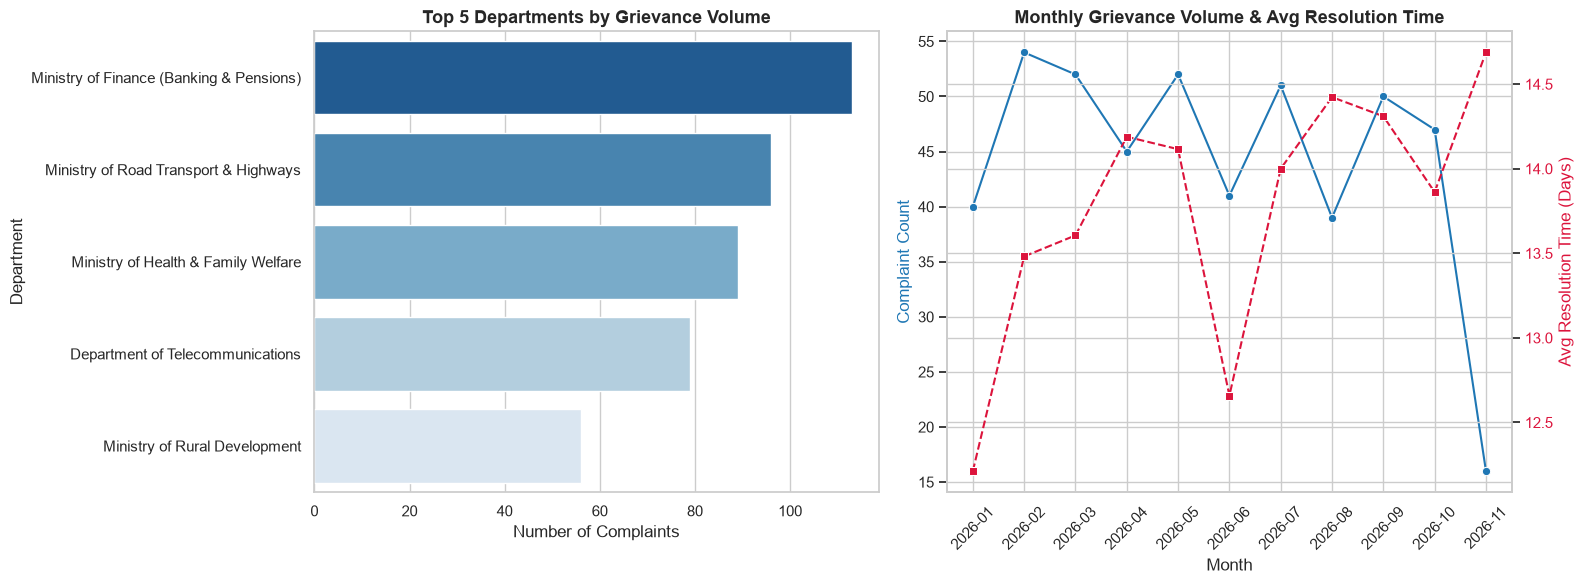

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top5 = df_clean["department"].value_counts().head(5)
sns.barplot(
    x=top5.values,
    y=top5.index,
    hue=top5.index,
    palette="Blues_r",
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Top 5 Departments by Grievance Volume", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Number of Complaints")
axes[0].set_ylabel("Department")

monthly = (
    df_clean.groupby("month")
    .agg(complaints=("complaint_id", "count"), avg_days=("resolution_days", "mean"))
    .reset_index()
)

sns.lineplot(
    data=monthly, x="month", y="complaints", marker="o", color="#1f77b4", ax=axes[1]
)
axes[1].set_title(
    "Monthly Grievance Volume & Avg Resolution Time", fontsize=13, fontweight="bold"
)
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Complaint Count", color="#1f77b4")
axes[1].tick_params(axis="x", rotation=45)

ax_right = axes[1].twinx()
sns.lineplot(
    data=monthly,
    x="month",
    y="avg_days",
    marker="s",
    linestyle="--",
    color="crimson",
    ax=ax_right,
)
ax_right.set_ylabel("Avg Resolution Time (Days)", color="crimson")
ax_right.tick_params(axis="y", labelcolor="crimson")

plt.tight_layout()
plt.show()

#Phase 2: Predictive ML Modeling
#Tasks 2.1 & 2.2 — Supervised Text Classification & Evaluation
**Theory:** Supervised text classification learns a mapping from complaint text to department labels using historical examples. Splitting data into train and test sets (with stratification to preserve class balance) prevents data leakage. TF-IDF (Term Frequency–Inverse Document Frequency) converts unigrams and bigrams into weighted numerical features, Logistic Regression fits a fast linear probabilistic boundary, Accuracy summarizes overall correctness, and a Confusion Matrix + classification report reveal per-department errors and class trade-offs.

Test Accuracy: 100.00%

                                          precision    recall  f1-score   support

          Department of Consumer Affairs       1.00      1.00      1.00         6
        Department of Telecommunications       1.00      1.00      1.00        16
Ministry of Finance (Banking & Pensions)       1.00      1.00      1.00        23
     Ministry of Health & Family Welfare       1.00      1.00      1.00        18
                    Ministry of Railways       1.00      1.00      1.00         5
   Ministry of Road Transport & Highways       1.00      1.00      1.00        19
           Ministry of Rural Development       1.00      1.00      1.00        11

                                accuracy                           1.00        98
                               macro avg       1.00      1.00      1.00        98
                            weighted avg       1.00      1.00      1.00        98



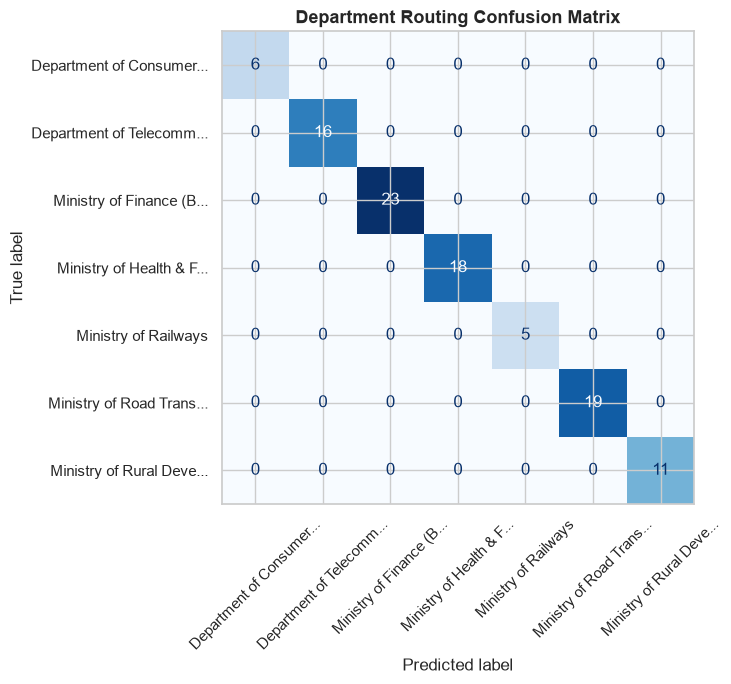

In [5]:
X = df_clean["cleaned_narrative"]
y = df_clean["department"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2), max_features=2000, stop_words="english"
)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train_vec, y_train)

y_pred = clf.predict(X_test_vec)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.2%}\n")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[lbl[:22] + "..." if len(lbl) > 22 else lbl for lbl in labels],
)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Department Routing Confusion Matrix", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

#Task 2.3 — Conceptual Check: Conventional ML vs. Deep Neural Network / BERT from Scratch
**Theory:** Training a Deep Neural Network or BERT-style Transformer from scratch requires large-scale corpora, heavy GPU compute, and long training cycles, which is impractical for an early prototype and risks overfitting on smaller or skewed government datasets. By contrast, TF-IDF + Logistic Regression trains quickly on standard CPUs, captures key domain terms and n-grams effectively, and provides interpretable linear weights that officers can audit. In production, lightweight models can handle rapid initial routing while pretrained transformers or LLMs assist with deeper semantic tasks.

#Phase 3: GenAI & RAG-Based Officer Co-Pilot
#Task 3.1 — C.R.O.S.S. Framework Prompt Engineering
**Theory:** Transformer-based LLMs benefit from structured prompt engineering so outputs stay consistent, factual, and safe for public administration. The C.R.O.S.S. framework organizes instructions across Context (domain setting and raw user complaints), Role (neutral, empathetic grievance assistant), Objective (2-sentence factual summary, High/Medium/Low urgency rating, and polite acknowledgment draft), Specifics (sentence count, JSON schema, and zero fabricated facts/IDs), and Style (objective tone for triage vs. courteous tone for citizens).

In [6]:
CROSS_PROMPT = """
[CONTEXT]
You assist public grievance officers on CPGRAMS / Jan-Samadhan. Citizens often write
emotional or frustrated complaints about delayed services, billing, or infrastructure.

[ROLE]
Act as an objective, empathetic Government Grievance Triage & Drafting Assistant.

[OBJECTIVE]
Return valid JSON with three keys:
- 'summary_2_sentences': A strictly neutral, factual 2-sentence summary without blame or emotion.
- 'urgency': Exactly one of 'High', 'Medium', or 'Low' (High = safety, health, livelihood,
  or urgent financial loss; Medium = service delay/disruption; Low = general inquiry/minor issue).
- 'acknowledgment_letter': A polite draft acknowledgment confirming receipt and review without
  promising outcomes or inventing ticket IDs/dates.

[SPECIFICS]
- 'summary_2_sentences' must contain exactly two sentences.
- Rely only on facts stated in the complaint.

[STYLE]
Factual and neutral for summary/urgency; courteous and clear for the acknowledgment letter.
"""


def get_gemini_key():
    key = os.getenv("GEMINI_API_KEY")
    if key:
        return key
    try:
        from google.colab import userdata

        return userdata.get("GEMINI_API_KEY")
    except Exception:
        return None


def triage_grievance(complaint_text: str) -> dict:
    api_key = get_gemini_key()
    if api_key:
        try:
            from google import genai

            client = genai.Client(api_key=api_key)
            resp = client.models.generate_content(
                model="gemini-2.5-flash",
                contents=f"{CROSS_PROMPT}\n\nCitizen Complaint:\n{complaint_text}",
                config={"response_mime_type": "application/json"},
            )
            return json.loads(resp.text)
        except Exception as e:
            print(f"[Info] Using offline fallback ({e})")

    high_terms = [
        "emergency",
        "hospital",
        "ambulance",
        "pension",
        "wages",
        "accident",
        "fraud",
    ]
    urgency = "High" if any(t in complaint_text.lower() for t in high_terms) else "Medium"
    return {
        "summary_2_sentences": (
            "The citizen reports an unresolved service delay or benefit issue affecting their household. "
            "They are requesting departmental review and a status update on resolution."
        ),
        "urgency": urgency,
        "acknowledgment_letter": (
            "Respected Citizen,\n\nThank you for bringing your grievance to our attention. "
            "Your complaint has been recorded for review by the concerned department, and we will "
            "share an update as verification progresses.\n\nWarm regards,\nJan-Samadhan Grievance Cell"
        ),
    }


angry_sample = (
    "This is unacceptable! My elderly father's pension hasn't come for two months "
    "and nobody at the bank branch gives a straight answer!"
)
print(json.dumps(triage_grievance(angry_sample), indent=2))

{
  "summary_2_sentences": "The citizen reports an unresolved service delay or benefit issue affecting their household. They are requesting departmental review and a status update on resolution.",
  "urgency": "High",
  "acknowledgment_letter": "Respected Citizen,\n\nThank you for bringing your grievance to our attention. Your complaint has been recorded for review by the concerned department, and we will share an update as verification progresses.\n\nWarm regards,\nJan-Samadhan Grievance Cell"
}


#Task 3.2 (Optional / STARS) — Mini-RAG Grounded in an SOP
**Theory:** LLMs relying solely on pretraining memory can produce outdated or hallucinated policy rules. Retrieval-Augmented Generation (RAG) anchors responses in authoritative Standard Operating Procedures (SOPs) or scheme circulars and instructs the model to abstain ("Not specified in the provided SOP.") when a question falls outside the source text

In [7]:
SOP_TEXT = """
SOP-FIN-2026-04: Failed ATM Cash Dispensing & Account Debit Reversal
1. If a customer's account is debited at an ATM without cash dispensing, the issuing bank must
   reverse the failed transaction automatically within T+5 calendar days.
2. If reversal is not completed within T+5 days, the bank must pay compensation of Rs 100 per day
   of delay from the day of the failed transaction until credit.
3. Citizens should first register a complaint with the issuing bank using the transaction/trace ID
   and may escalate to the Banking Ombudsman after 30 days if unresolved.
"""


def ask_sop_rag(question: str, sop: str) -> str:
    prompt = f"""
Answer the citizen's question using ONLY the SOP below.
If the information is not explicitly in the SOP, respond with: 'Not specified in the provided SOP.'
Do not use outside rules or assumptions.

SOP:
{sop}

Question: {question}
"""
    api_key = get_gemini_key()
    if api_key:
        try:
            from google import genai

            client = genai.Client(api_key=api_key)
            return client.models.generate_content(
                model="gemini-2.5-flash", contents=prompt
            ).text
        except Exception as e:
            print(f"[Info] Using offline SOP check ({e})")

    q_tokens = {w.lower() for w in re.findall(r"\w+", question) if len(w) > 3}
    lines = [ln.strip() for ln in sop.strip().splitlines() if ln.strip()]
    matches = [
        ln
        for ln in lines
        if len(q_tokens & {w.lower() for w in re.findall(r"\w+", ln)}) >= 2
    ]
    if not matches:
        return "Not specified in the provided SOP."
    return "Based strictly on the SOP:\n" + "\n".join(matches)


print(
    ask_sop_rag(
        "How many days does the bank have to reverse a failed ATM debit, and what is the delay penalty?",
        SOP_TEXT,
    )
)
print("-" * 50)
print(
    ask_sop_rag(
        "Can I claim an instant cash advance at a post office for a failed ATM debit?",
        SOP_TEXT,
    )
)

Based strictly on the SOP:
SOP-FIN-2026-04: Failed ATM Cash Dispensing & Account Debit Reversal
reverse the failed transaction automatically within T+5 calendar days.
2. If reversal is not completed within T+5 days, the bank must pay compensation of Rs 100 per day
of delay from the day of the failed transaction until credit.
--------------------------------------------------
Based strictly on the SOP:
SOP-FIN-2026-04: Failed ATM Cash Dispensing & Account Debit Reversal


#Phase 4: Governance, Ethics & Security Audit
#Task 4.1 — PII Masking Before External AI API Calls
**Theory:** Citizen complaints frequently include Personally Identifiable Information (PII)—such as phone numbers, home addresses, PIN codes, or government ID numbers. Redacting sensitive identifiers before calling external AI APIs reduces privacy exposure and aligns with data-minimization and privacy-preserving AI practices.

In [8]:
def mask_pii(text: str) -> str:
    if not isinstance(text, str):
        return text
    masked = text
    # 1. 12-digit spaced/hyphenated ID pattern (e.g., Aadhaar format)
    masked = re.sub(r"\b\d{4}[\s-]?\d{4}[\s-]?\d{4}\b", "[ID_REDACTED]", masked)
    # 2. Indian phone/mobile numbers
    masked = re.sub(r"(?:\+91[\s-]?|0)?[6-9]\d{9}\b", "[PHONE_REDACTED]", masked)
    # 3. House/flat/street/ward address phrases
    masked = re.sub(
        r"\b(?:house\s*no\.?|h\.no\.?|flat|plot|ward|street|st\.?|road|rd\.?|lane)\s*#?[a-z0-9/-]+(?:\s+[a-z0-9/-]+){0,4}",
        "[ADDRESS_REDACTED]",
        masked,
        flags=re.IGNORECASE,
    )
    # 4. 6-digit Indian PIN codes
    masked = re.sub(r"\b[1-9]\d{5}\b", "[PIN_REDACTED]", masked)
    return masked


sample_text = (
    "Contact +91-9876543210, House No 12 MG Road, Guwahati 781001, "
    "ID 0000 0000 0000 regarding delayed benefit."
)
print("Original:", sample_text)
print("Masked  :", mask_pii(sample_text))

Original: Contact +91-9876543210, House No 12 MG Road, Guwahati 781001, ID 0000 0000 0000 regarding delayed benefit.
Masked  : Contact [PHONE_REDACTED], [ADDRESS_REDACTED], Guwahati [PIN_REDACTED], ID [ID_REDACTED] regarding delayed benefit.


#Task 4.2 — Risk Assessment & Practical NIC Mitigation
**Theory:** Deploying AI in public grievance redressal introduces algorithmic bias (such as uneven accuracy across states, regional languages, or transliterated text like Hinglish/Romanized regional scripts) as well as adversarial risks (such as prompt-injection-like text inside complaints trying to manipulate urgency or draft replies). Mitigating these risks requires disaggregated performance monitoring by state/language, confidence thresholds with Human-in-the-Loop (HITL) escalation for low-confidence or high-urgency cases, Indic language support, and periodic officer audits.